In [4]:
### Required libraries
import numpy as np
import matplotlib.pyplot as plt
import torch
import math
from torch_fourier_slice.slice_insertion._insert_central_slices_rfft_3d import (
    insert_central_slices_rfft_3d,
)
from torch_ctf import calculate_ctf_2d
from torch_affine_utils.transforms_3d import Ry

# optional
use_napari = True
if use_napari:
    from napari import Viewer


In [5]:
def generate_sphere(box_size, sphere_radius, pixel_size, location=None):
    """Sphere(s) with a soft (one-voxel linear) edge, normalised to [0, 1].

    location: None (box centre), one (x, y, z) centre, or a list of (x, y, z)
    centres, in the same units as box_size. All spheres are added together and
    the result is divided by its maximum. Parts outside the box are cut off.
    """
    grid_dim = int(box_size // pixel_size)
    radius_idx = sphere_radius / pixel_size
    if location is None:
        centres = np.full((1, 3), box_size / 2.0)
    else:
        centres = np.atleast_2d(np.asarray(location, dtype=float))

    centres = centres / pixel_size
    z, y, x = np.ogrid[:grid_dim, :grid_dim, :grid_dim]
    volume = np.zeros((grid_dim,) * 3, dtype=np.float32)
    for cx, cy, cz in centres:
        dist = np.sqrt((x - cx) ** 2 + (y - cy) ** 2 + (z - cz) ** 2)
        volume += np.clip(radius_idx + 0.5 - dist, 0.0, 1.0)
    if volume.max() > 0:
        volume /= volume.max()

    return volume


def create_binary_wedge(
    shape: tuple[int, int, int],
    alpha_min_rad: float,
    alpha_max_rad: float,
    level_angle_x_rad: float = 0.0,
    device: torch.device | str = 'cpu',
    dtype: torch.dtype = torch.float32,
) -> torch.Tensor:
    """This function returns a wedge object, built directly from the extreme
    tilt angles.

    Parameters
    ----------
    shape: tuple[int, int, int]
        real space shape of volume to which it needs to be applied
    alpha_min_rad: float
        lowest tilt angle (including level_angle_y) in radians, in [-pi/2, pi/2]
    alpha_max_rad: float
        highest tilt angle (including level_angle_y) in radians, in [-pi/2, pi/2]
    cut_off_radius: float
        cutoff as a fraction of nyquist, i.e. 1.0 means all the way to nyquist
    level_angle_x_rad: float, default 0.0
        WarpTools sample-leveling angle in radians that rotates the wedge around the
        x-axis
    device: torch.device | str | None, default None
        device on which to build the wedge
    dtype: torch.dtype, default torch.float32
        floating point dtype of the returned wedge

    Returns
    ----------
    wedge: torch.Tensor
        wedge volume that is a reduced fourier space object in z, i.e. shape[2] // 2 + 1
    """
    if abs(alpha_min_rad) > math.pi / 2 or abs(alpha_max_rad) > math.pi / 2:
        raise ValueError(
            "alpha_min_rad and alpha_max_rad (tilt angle plus level_angle_y) must "
            "lie within [-90, 90] degrees"
        )
    
    z = -(
        torch.fft.fftfreq(shape[0], device=device, dtype=dtype)
        * shape[0] / (shape[0] // 2)
    )[:, None, None]
    y = (
        torch.fft.fftfreq(shape[1], device=device, dtype=dtype)
        * shape[1] / (shape[1] // 2)
    )[None, :, None]
    x = (
        torch.fft.rfftfreq(shape[2], device=device, dtype=dtype)
        * shape[2] / (shape[2] // 2)
    )[None, None, :]

    # z rotated by level_angle_x_rad within the (y, z) plane - see docstring
    z_eff = z * math.cos(level_angle_x_rad) - y * math.sin(level_angle_x_rad)

    r = torch.sqrt(x**2 + z_eff**2)
    phi = torch.atan2(x, z_eff)

    f_min = x * math.sin(alpha_min_rad) + z_eff * math.cos(alpha_min_rad)
    f_max = x * math.sin(alpha_max_rad) + z_eff * math.cos(alpha_max_rad)
    phi_in_range = (phi >= alpha_min_rad) & (phi <= alpha_max_rad)

    lo = torch.minimum(f_min, f_max)
    hi = torch.where(phi_in_range, r, torch.maximum(f_min, f_max))

    # positive inside the sampled interval, negative outside, continuous and zero
    # at the boundary
    wedge = (torch.minimum(-lo, hi) >= 0).to(dtype)

    radius = torch.sqrt(x**2 + y**2 + z**2)
    wedge[radius > 1.0] = 0

    return wedge


def radial_grid(
    shape: tuple[int, int, int],
    device: torch.device | str = 'cpu',
    dtype: torch.dtype = torch.float32,
) -> torch.Tensor:
    """Calculates a Fourier space radial grid for a 3D shape whose last dimension
    is already reduced (i.e. the shape of an rfftn output). Values range from 0 at
    the 0 frequency to 1 at Nyquist frequency. The 0 frequency sits at index 0 of
    each axis (not fftshifted).

    Parameters
    ----------
    shape: tuple[int, int, int]
        reduced 3D Fourier shape, i.e. (nx, ny, nz // 2 + 1)
    device: torch.device | str | None, default None
        device on which to build the grid
    dtype: torch.dtype, default torch.float32
        floating point dtype of the returned grid

    Returns
    ----------
    radial_grid: torch.Tensor
        Fourier space frequency grid of the given shape
    """
    if len(shape) != 3:
        raise ValueError("radial_grid() only works for 3D shapes")

    x = torch.fft.fftfreq(shape[0], d=1, device=device, dtype=dtype)
    y = torch.fft.fftfreq(shape[1], d=1, device=device, dtype=dtype)
    z = torch.fft.rfftfreq(shape[2], d=1, device=device, dtype=dtype)

    return torch.sqrt(x[:, None, None]**2 + y[None, :, None]**2 + z[None, None, :]**2)

    
def create_slice_inserted_wedge(volume_shape, tilt_angles, ctf_values=None, device="cpu"):
    size = volume_shape[-1]
    frequency_grid = radial_grid(volume_shape, device=device)

    images = torch.ones((len(tilt_angles), size, size//2 + 1), dtype=torch.float32, device=device)

    if ctf_values is not None:
        ctf_image = torch.abs(calculate_ctf_2d(**ctf_values))
        images = torch.stack([ctf_image] * len(tilt_angles))

    # [:3, :3] crops affine matrices to pure rotation matrices
    rotation_matrices = Ry(tilt_angles, device=device)[..., :3, :3]
    
    dft, weights = insert_central_slices_rfft_3d(
        image_rfft=images,
        volume_shape=volume_shape,
        rotation_matrices=rotation_matrices,
        fftfreq_max=0.5,
        zyx_matrices=False,
    )

    weights = torch.clamp(weights, min=1.0)
    dft /= weights

    dft = torch.fft.ifftshift(dft, dim=(-3, -2))

    dft[frequency_grid > 0.5] = 0

    return dft

In [6]:
def plot_3d_data(data, threshold=None, percentile=95, grey_scale=False):
    """
    Plot voxels of a continuous 3D field above a threshold.
    If threshold is None, it's set automatically using `percentile`
    (e.g. top 5% of intensity values).
    """
    if threshold is None:
        threshold = np.percentile(data, percentile)

    x, y, z = np.where(data >= threshold)
    values = data[x, y, z]

    fig = plt.figure()
    ax = fig.add_subplot(projection='3d')

    if grey_scale:
        sc = ax.scatter(x, y, z, c=values, cmap='gray_r', s=2, alpha=0.3)
    else:
        sc = ax.scatter(x, y, z, c=values, cmap='viridis', s=2)
    fig.colorbar(sc, ax=ax, shrink=0.6, label='Intensity')

    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.set_zlabel('Z')
    ax.set_xlim(0, data.shape[0])
    ax.set_ylim(0, data.shape[1])
    ax.set_zlim(0, data.shape[2])
    ax.set_title(f'Voxels above threshold={threshold:.3f}')

    plt.show()


def plot_slice(data, axis=0, index=None, threshold_bar=True, label_bool=True):
    """
    Plot a 2D slice of a 3D field along the specified axis.
    If index is None, the middle slice is plotted.
    """
    if index is None:
        index = data.shape[axis] // 2

    if axis == 0:
        slice_data = data[index, :, :]
    elif axis == 1:
        slice_data = data[:, index, :]
    elif axis == 2:
        slice_data = data[:, :, index]
    else:
        raise ValueError("Axis must be 0, 1, or 2.")

    plt.figure()
    plt.imshow(slice_data.T, origin='lower', cmap='gray', vmin=np.min(slice_data), vmax=np.max(slice_data))
    if threshold_bar:
        plt.colorbar(label='Intensity')
    if axis == 2:
        plt.title(f'Slice along axis {axis} at z = {index}')
    if axis == 1:
        plt.title(f'Slice along axis {axis} at y = {index}')
    if axis == 0:
        plt.title(f'Slice along axis {axis} at x = {index}')
    if label_bool:
        plt.xlabel('X-axis' if axis != 0 else 'Y-axis')
        plt.ylabel('Y-axis' if axis != 1 else 'Z-axis')
    plt.show()

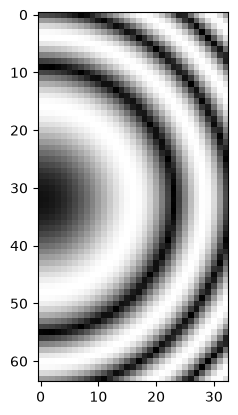

In [7]:
# test CTF generation
ctf_values = {
    "defocus": 3,  # in micrometers
    "astigmatism": 0.0,  # in micrometers
    "astigmatism_angle": 0.0,  # in degrees
    "voltage": 200,  # in volts
    "spherical_aberration": 2.7, # mm float | torch.Tensor,
    "amplitude_contrast": 0.07, # float | torch.Tensor,
    "phase_shift": 0.0, # float | torch.Tensor,
    "pixel_size": 10, # float | torch.Tensor,
    "image_shape": (64, 64), # tuple[int, int],
    "rfft": True, # bool,
    "fftshift": True, # bool,
    "beam_tilt_mrad": None, # torch.Tensor | None = None,
    "even_zernike_coeffs": None, # dict | None = None,
    "odd_zernike_coeffs": None, # dict | None = None,
    "transform_matrix": None, # torch.Tensor | None = None,
    "return_complex_ctf": False, # bool = False, 
}
ctf_image = torch.abs(calculate_ctf_2d(**ctf_values))
plt.imshow(ctf_image.numpy(), cmap='gray')

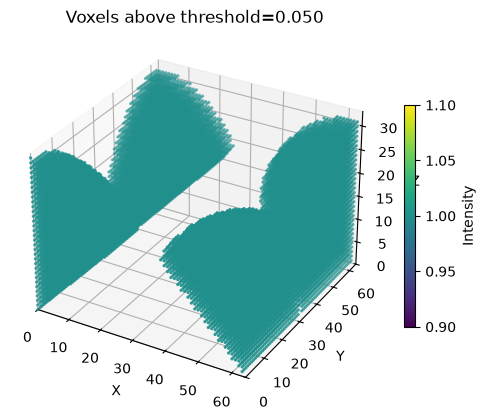

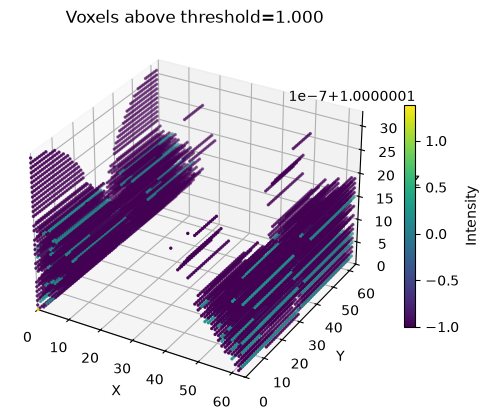

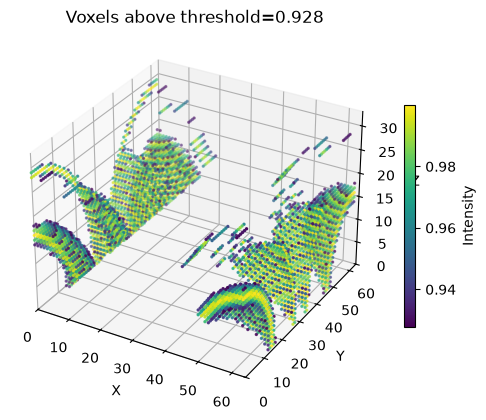

In [8]:
# create wedge_models
tilt_angles = torch.arange(-54, 57, 3)
box_size = 64
perfect_data = generate_sphere(box_size=box_size, sphere_radius=8, pixel_size=1)
ctf_values["image_shape"] = (box_size, ) * 2

# create DeepDeWedge missing wedge mask
binary_missing_wedge = create_binary_wedge(
    shape=perfect_data.shape, 
    alpha_min_rad=np.deg2rad(tilt_angles.min().item()),
    alpha_max_rad=np.deg2rad(tilt_angles.max().item())
)
plot_3d_data(binary_missing_wedge, threshold=0.05)

# create slice inserted wedge with the help of teamtomo
slice_inserted_wedge = create_slice_inserted_wedge(
    volume_shape=perfect_data.shape, 
    tilt_angles=tilt_angles, 
    ctf_values=None
)
plot_3d_data(slice_inserted_wedge)

# Insert the 2D CTF slices; the first return value is the CTF-weighted Fourier volume.
d_ctf = create_slice_inserted_wedge(
    volume_shape=perfect_data.shape, 
    tilt_angles=tilt_angles, 
    ctf_values=ctf_values
)
plot_3d_data(d_ctf.numpy(), grey_scale=False)
masks = [binary_missing_wedge, slice_inserted_wedge, d_ctf]

# if use_napari:
#     viewer = Viewer()
#     [viewer.add_image(m.numpy()) for m in masks]


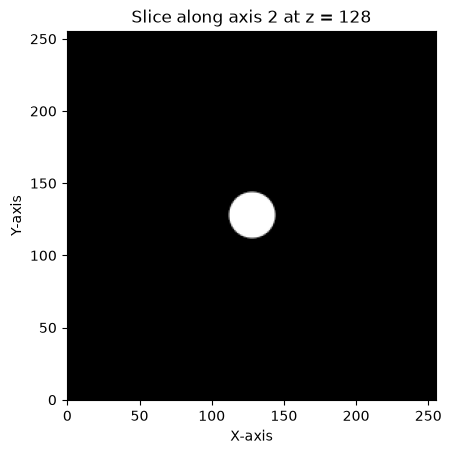

(3, 256, 256, 256)


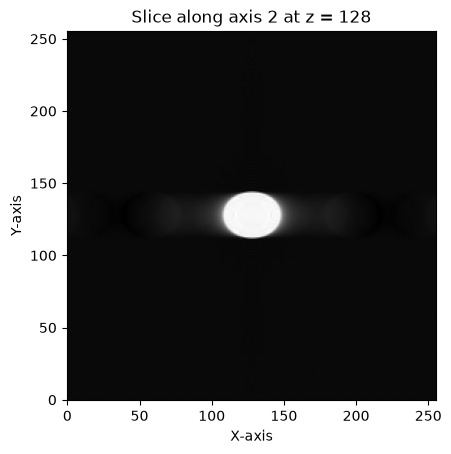

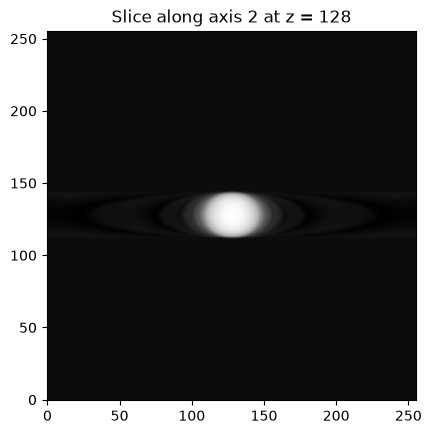

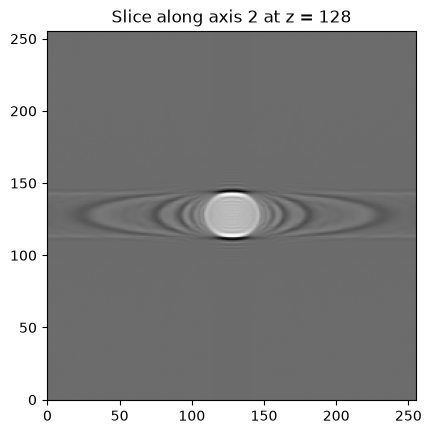

In [16]:
def _run_example(axis=1, napari_viewer=False, index=box_size//2):
    # create DeepDeWedge missing wedge mask
    binary_missing_wedge = create_binary_wedge(
        shape=perfect_data.shape, 
        alpha_min_rad=np.deg2rad(tilt_angles.min().item()),
        alpha_max_rad=np.deg2rad(tilt_angles.max().item())
    )
    
    # create slice inserted wedge with the help of teamtomo
    slice_inserted_wedge = create_slice_inserted_wedge(
        volume_shape=perfect_data.shape, 
        tilt_angles=tilt_angles, 
        ctf_values=None
    )
    
    # Insert the 2D CTF slices; the first return value is the CTF-weighted Fourier volume.
    d_ctf = create_slice_inserted_wedge(
        volume_shape=perfect_data.shape, 
        tilt_angles=tilt_angles, 
        ctf_values=ctf_values
    )
    masks = [binary_missing_wedge, slice_inserted_wedge, d_ctf]
    convolved_images = np.zeros((len(masks), perfect_data.shape[0], perfect_data.shape[1], perfect_data.shape[2]))
    print(np.shape(convolved_images))
    
    # Apply fftn to sphere data
    perfect_data_fft = torch.fft.rfftn(torch.Tensor(perfect_data))

    if napari_viewer:
        viewer = Viewer()
    
    for n, mask in enumerate(masks):
        convolved = torch.fft.irfftn(perfect_data_fft * mask).numpy()

        # difference_convolved = convolved - perfect_data

        convolved_images[n] = convolved

        # plot_slice(difference_convolved, axis=axis, index=index, threshold_bar=False, label_bool=False)
    
        # plot_slice(torch.abs(perfect_data_fft * mask).numpy(), axis=axis, index=0)
    
        # plot_3d_data(convolved_real, threshold=0.01, percentile=95, grey_scale=True)
        if n == 0:
            plot_slice(convolved, axis=axis, index=index, threshold_bar=False, label_bool=True)
        else:
            plot_slice(convolved, axis=axis, index=index, threshold_bar=False, label_bool=False)

        if napari_viewer:
            viewer.add_image(convolved, name=f'Mask {n + 1}')

    return convolved_images

# create wedge_models
tilt_angles = torch.arange(-54, 57, 9)
box_size = 256
perfect_data = generate_sphere(box_size=box_size, sphere_radius=16, pixel_size=1, location=[(box_size//2, box_size//2, box_size//2)])
ctf_values["image_shape"] = (box_size, ) * 2
plot_slice(perfect_data, axis=2, index=box_size//2, threshold_bar=False, label_bool=True)
cvs = _run_example(axis=2, napari_viewer=False, index=box_size//2)

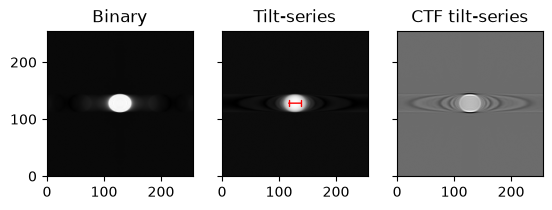

In [18]:
import matplotlib.lines as lines

cvs = cvs

titles = ["Binary", "Tilt-series", "CTF tilt-series"]

circle_center = [box_size//2, box_size//2]
radius = 16

fig, axs = plt.subplots(1, 3)
for i, cv in enumerate(cvs):
    slice = cv[:, :, box_size//2]
    axs[i].imshow(slice.T, origin='lower', cmap='gray', vmin=np.min(slice), vmax=np.max(slice))
    axs[i].set_title(titles[i])

    if i == 1:
        axs[i].annotate(
                    '', 
                    xy=(circle_center[0] - radius, circle_center[1]),  # Left edge 
                    xytext=(circle_center[0] + radius, circle_center[1]), # Right edge 
                    arrowprops=dict(
                        arrowstyle='|-|,widthA=0.2,widthB=0.2', # Bracket/tick ends
                        color='red',
                        lw=1                                  # Line width
                    )
                )

for ax in axs.flat:
    ax.label_outer()


(3, 256, 256, 256)


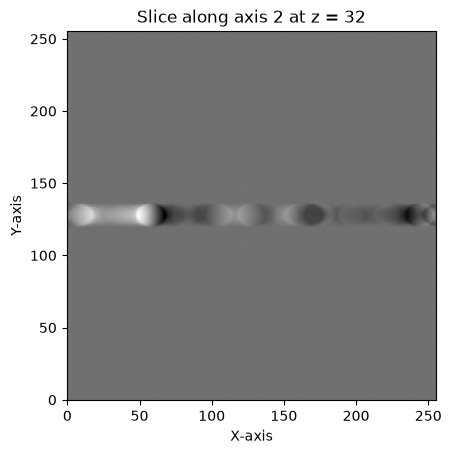

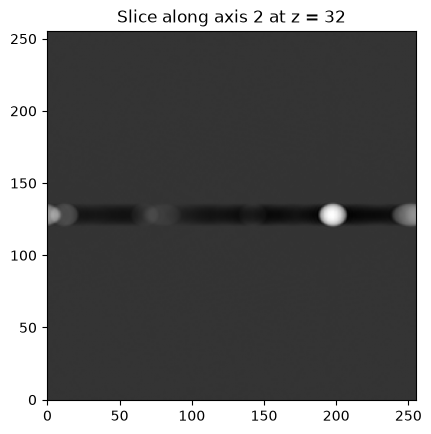

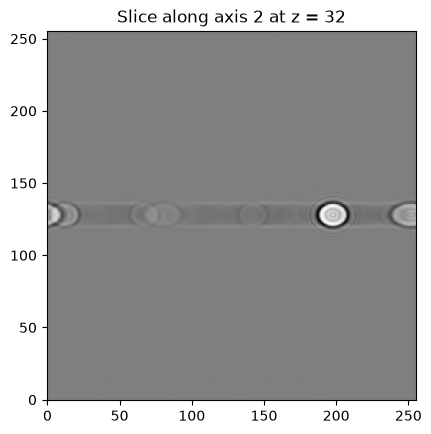

array([[[[ 1.53217523e-04, -8.02333743e-05,  1.33203503e-05, ...,
           5.99175801e-05,  1.33203794e-05, -8.02331488e-05],
         [ 2.81379653e-06, -4.14823153e-05,  3.17908380e-05, ...,
          -4.50404623e-05,  3.17910562e-05, -4.14819515e-05],
         [ 2.30215046e-05,  5.56054147e-06,  2.78424759e-05, ...,
          -3.45556073e-05,  2.78424450e-05,  5.56086525e-06],
         ...,
         [ 4.02328624e-05, -5.66824674e-05,  2.98739633e-06, ...,
           1.28950969e-05,  2.98758914e-06, -5.66823328e-05],
         [ 2.30232636e-05,  5.56261148e-06,  2.78432271e-05, ...,
          -3.45548906e-05,  2.78430416e-05,  5.56197119e-06],
         [ 2.81426765e-06, -4.14822644e-05,  3.17906597e-05, ...,
          -4.50403058e-05,  3.17905069e-05, -4.14823262e-05]],

        [[ 8.58593048e-05, -2.70485780e-05,  3.44321052e-06, ...,
          -3.99887540e-06,  3.94697236e-05, -4.63327160e-05],
         [-3.18976781e-05, -3.92696165e-07,  1.85842146e-05, ...,
          -6.94424598e

In [11]:
# create wedge_models
tilt_angles = torch.arange(-54, 57, 30)
box_size = 256
perfect_data = generate_sphere(box_size=box_size, sphere_radius=8, pixel_size=1)
ctf_values["image_shape"] = (box_size, ) * 2

_run_example(axis=2)

In [12]:
# Insert the 2D CTF slices; the first return value is the CTF-weighted Fourier volume.
d_ctf = create_slice_inserted_wedge(
    volume_shape=perfect_data.shape, 
    tilt_angles=tilt_angles, 
    ctf_values=ctf_values
)

# Apply fftn to sphere data
perfect_data_fft = torch.fft.rfftn(torch.Tensor(perfect_data))
convolved = torch.fft.irfftn(perfect_data_fft * d_ctf).numpy()

viewer = Viewer()
viewer.add_image(convolved)

<Image layer 'convolved' at 0x235c4fc6510>